# Experiment log â€” start here

Read the numbered folders in order. Each README explains **what changed, implementation, results and interpretation**, with links to the original evidence. `Experiment_Log.ipynb` presents the same tables with saved outputs; no rerunning training is required to read it. `runs.json` is the machine-readable registry.

Two accuracy protocols exist: the historical 500-image pilot and the current 27,000-image training-set evaluation. They are separate tables. Remote device inference has a 32-image numerical check, not a new full-dataset accuracy score. All model changes still start from the supplied student.



In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display
project = Path.cwd()
if not (project / "edgeprep").exists(): project = project.parent
registry = json.loads((project / "experiments/runs.json").read_text())
display(pd.DataFrame([{k:r.get(k) for k in ["name","phase","status"]} for r in registry["records"]]))

,name,phase,status
0,baseline,historical_pilot,completed
1,qdq_s8,historical_pilot,completed
2,qdq_u8,historical_pilot,completed
3,qdq_s8_256,historical_pilot,completed
4,qdq_percentile,historical_pilot,completed
5,qdq_protected,historical_pilot,completed
6,qdq_pointwise,historical_pilot,completed
7,prune05,historical_pilot,completed
8,prune10,historical_pilot,completed
9,expansion05,historical_pilot,completed


# 01. Original models and dataset

Verified supplied MobileNetV2 and optional ResNet50, exact safe checkpoint loading, fixed 224 input, all 27,000 EuroSAT files and preprocessing. MobileNetV2 has 2,236,682 parameters; ResNet50 is the teacher, never the denominator.



# 02. Historical compression and short recovery

Before the organizer clarification, 13 variants were screened on 500 images from a provisional split. The table follows the experimental progression, not reconstructed timestamps. Full quantization, selective quantization, physical pruning, and short CE/KD recovery are different operations. CE/KD used only 500 training images for one epoch. These rows cannot be mixed with current all-data ratios.



In [2]:
rows = [r for r in registry["records"] if r["phase"] == 'historical_pilot' and r["name"] in ['baseline', 'qdq_s8', 'qdq_u8', 'qdq_s8_256', 'qdq_percentile', 'qdq_protected', 'qdq_pointwise', 'prune05', 'prune10', 'expansion05', 'expansion10', 'expansion05_ce', 'expansion05_kd']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'examples']} for r in rows]).round(4))

,name,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,examples
0,baseline,99.2,96.0,8.5063,2.1668,500
1,qdq_s8,92.6,66.0,2.5256,5.6622,500
2,qdq_u8,91.4,58.0,2.5414,4.3796,500
3,qdq_s8_256,91.0,66.0,2.5257,5.2509,500
4,qdq_percentile,96.2,80.0,2.5255,5.7884,500
5,qdq_protected,96.0,90.0,3.7159,6.0622,500
6,qdq_pointwise,98.4,94.0,3.7720,5.3334,500
7,prune05,16.0,0.0,7.6219,1.8400,500
8,prune10,17.2,0.0,6.9353,1.6972,500
9,expansion05,83.2,46.0,8.1381,2.6330,500


# 03. Our current unchanged-student baseline

After the organizer clarified all-data training and our own laptop reference, evaluated the unchanged student on all 27,000 images. This is training-set accuracy. Exported FP32 ONNX and measured serial CPU runtime/RAM/estimated energy. No recovery or retraining.



In [3]:
rows = [r for r in registry["records"] if r["phase"] == 'current_all_data' and r["name"] in ['baseline']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'examples']} for r in rows]).round(4))

,name,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,examples
0,baseline,99.163,95.84,8.5063,2.1036,27000


# 04. Selective INT8 with 256 MinMax samples

Quantized pointwise convolutions while preserving first/last layers, classifier and depthwise convolutions in FP32. Same learned parameters; smaller weight storage. Calibrated 256 balanced samples and evaluated all 27,000. Smaller does not mean faster: this graph regressed on our laptop CPU.



In [4]:
rows = [r for r in registry["records"] if r["phase"] == 'current_all_data' and r["name"] in ['qdq_pointwise']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'examples']} for r in rows]).round(4))

,name,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,examples
0,qdq_pointwise,98.4111,95.4333,3.772,5.1842,27000


# 05. Selective INT8 with 512 Percentile samples

Same selective precision pattern, now Percentile calibration and 512 balanced samples. This changes two knobs together; it screens a configuration but does not isolate the benefit of either algorithm or sample count. Full-data evaluation and fresh runtime measurements recorded when present.



In [5]:
rows = [r for r in registry["records"] if r["phase"] == 'current_all_data' and r["name"] in ['qdq_percentile512']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'accuracy_pct', 'worst_recall_pct', 'size_mib', 'median_cpu_4t_ms', 'examples']} for r in rows]).round(4))

,name,accuracy_pct,worst_recall_pct,size_mib,median_cpu_4t_ms,examples
0,qdq_percentile512,98.8037,95.36,3.7719,5.5206,27000


# 06. Real-device CPU/NPU deployment

Authenticated using the ignored .env key. Retrieved 78 catalogue entries. S24 CPU and NPU exploration, plus RB3 Hub-native W8A8 compilation. First S24 NPU inference failed because compute_unit and an explicit provider were both specified; the retry removes compute_unit from inference options. Remote 32-image agreement is a smoke check, never full-data accuracy. Preserve failures alongside successful runs.



In [6]:
rows = [r for r in registry["records"] if r["phase"] == 'remote_exploration' and r["name"] in ['s24_cpu_fp32', 's24_npu_float', 's24_npu_float_retry', 'rb3_npu_w8a8', 'rb3_onnx_npu_w8a8']]
display(pd.DataFrame([{k:r.get(k) for k in ['name', 'status', 'device', 'precision', 'hub_estimated_latency_ms', 'top1_agreement_pct']} for r in rows]).round(4))

,name,status,device,precision,hub_estimated_latency_ms,top1_agreement_pct
0,s24_cpu_fp32,completed,Samsung Galaxy S24 (Family),none,5.533,100.0
1,s24_npu_float,failed,Samsung Galaxy S24 (Family),none,NaN,NaN
2,s24_npu_float_retry,completed,Samsung Galaxy S24 (Family),none,0.366,100.0
3,rb3_npu_w8a8,failed,Dragonwing RB3 Gen 2 Vision Kit,w8a8,NaN,NaN
4,rb3_onnx_npu_w8a8,pending,Dragonwing RB3 Gen 2 Vision Kit,w8a8,NaN,NaN


# 07. Next experiments, not yet measured

Prioritize same-device W8A8 vs W8A16, fixed-count MSE vs MinMax calibration, beta Lite-MP, 1-2% expansion pruning with full-data CE/KD, and BN recalibration. Compare every candidate against a reference on the same device/runtime. No full-data recovery training has been completed yet.



## Current all-data tradeoff
Training-set accuracy; same laptop and input contract. Remote device results stay separate.

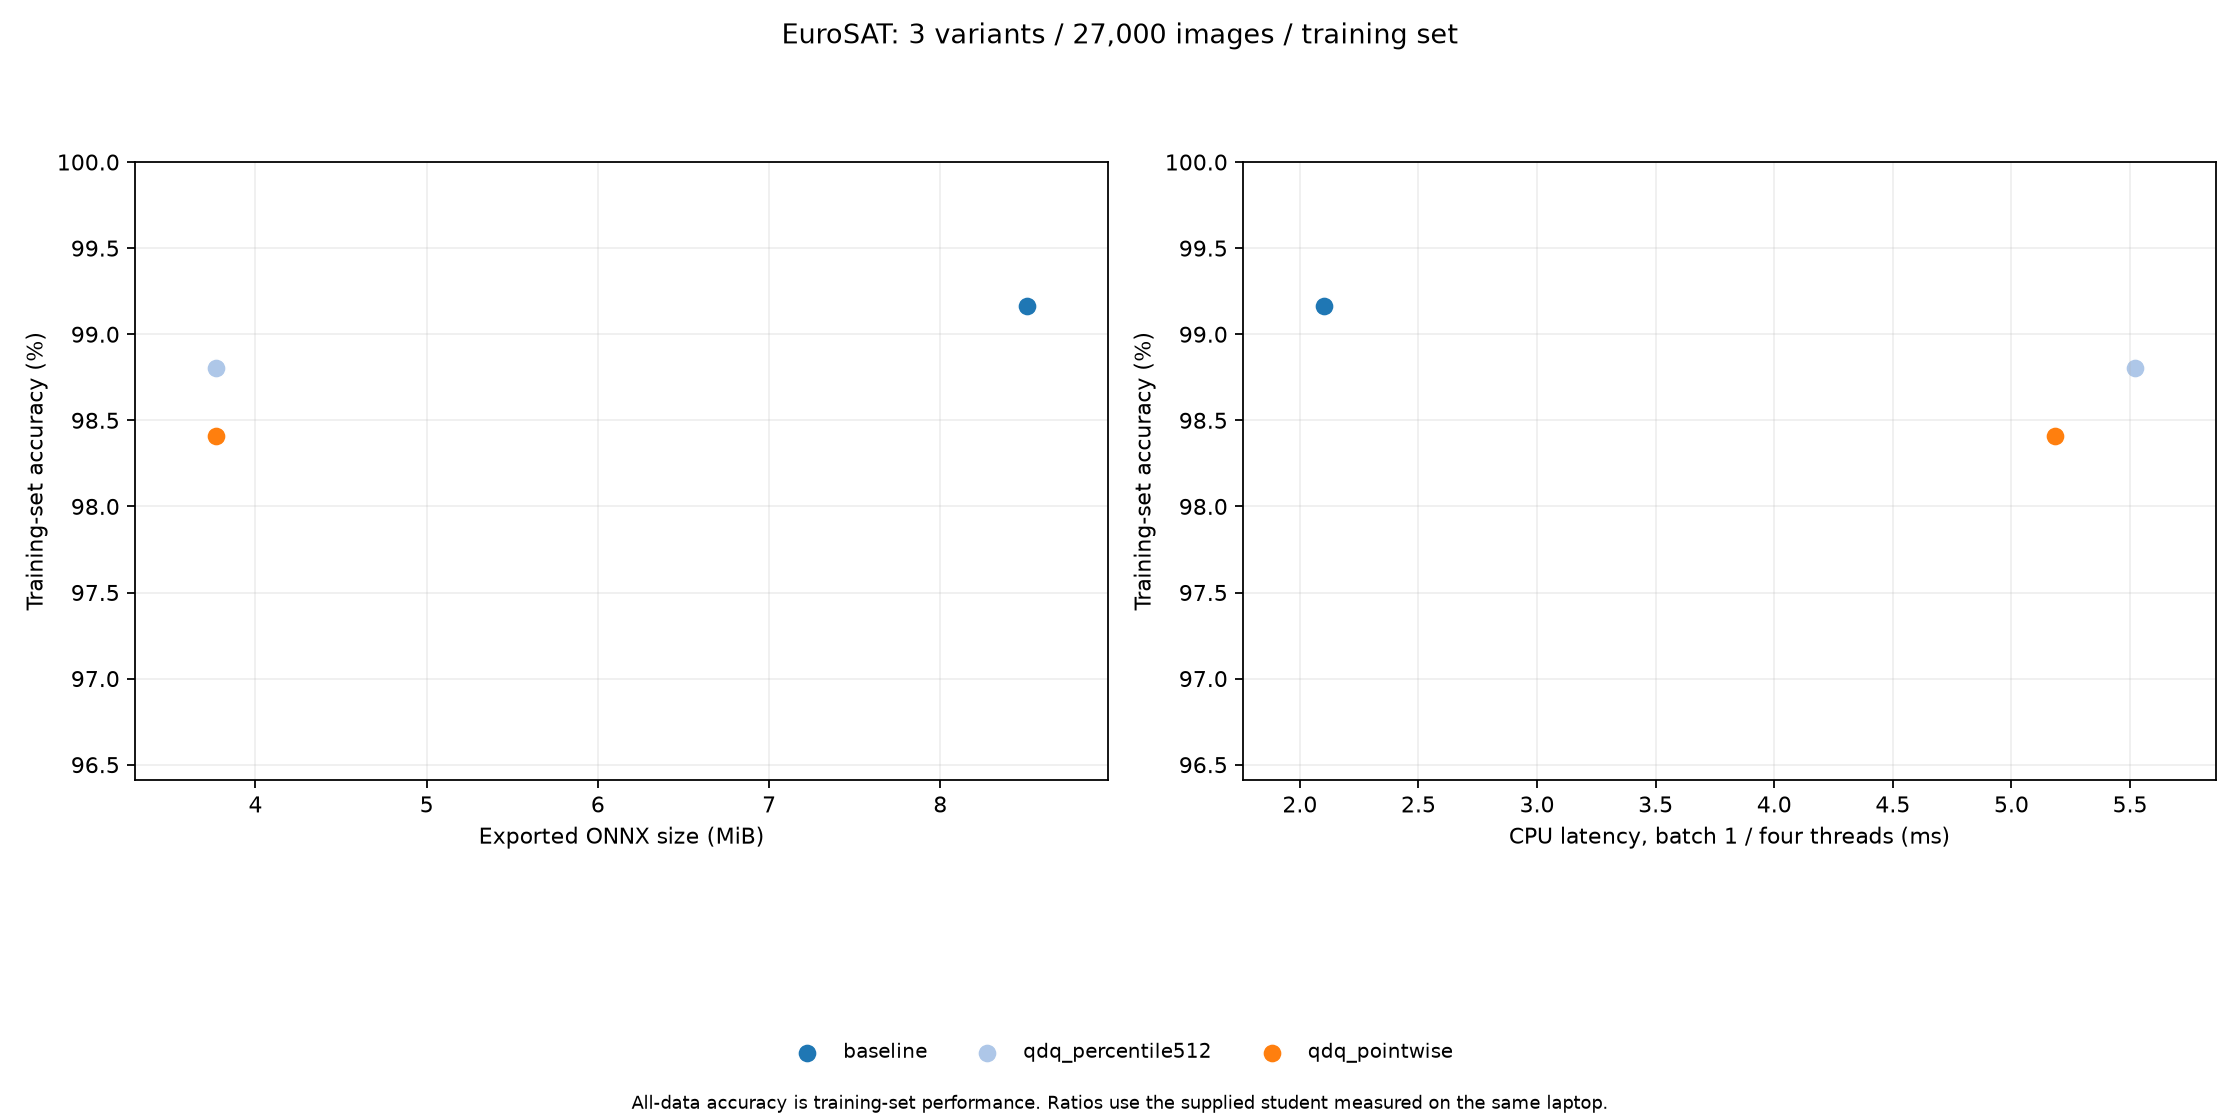

In [7]:
from IPython.display import Image
display(Image(filename=str(project / "results/all_data/tradeoff.png")))